# EDA – Marktabgrenzung & ESCO-Labels („Keksausstecher“)

Vorbereitende Analyse für Stufe 2 von Ziel 1 (Rankingabstand der Zwillinge): Bevor wir
Zwillinge erzeugen, brauchen wir einen **abgegrenzten Jobmarkt** – eine feste Bewerberliste
und passende Stellen, in denen ein Ranking von „passt sehr gut“ bis „passt kaum“ überhaupt
Sinn ergibt.

Leitfragen aus dem Backlog (06.10.2026, Tobi, *Welche CVs/Jobs?*):
- Welche Primary Keywords haben genug Jobs und CVs für einen Pool mit passenden und unpassenden Kandidat:innen?
- Welche ESCO-Labels matchen gut mit welchen CVs/Postings?
- (mit) Welche CV-Spalten geben wir ESCOX?

**Testdesign, auf das diese EDA hinarbeitet:**

| Baustein | Umfang | Herkunft |
|---|---|---|
| Zielberuf **A** | 1 Primary Keyword | fachliche Vorgabe des Teams, geprüft in dieser EDA |
| Bewerberliste | 60 CVs = 20 **A** (Kern) / 20 **B** (Nachbar) / 20 **C** (fremd, aber IT) | fest, eingefroren |
| Stellen | 20 Jobs aus **A** | fest, eingefroren |
| Zwillings-Quellen | 120 *andere* CVs: 70 A + 30 B (**Haupttest**, 100 Paare) + 20 C (**Kontrolle**) → 6 Paare pro Job | Input für die Zwillingsgenerierung |

Jeder Zwilling wird einzeln in die Bewerberliste eingereiht und für „seinen“ A-Job gerankt; der
Platzabstand der beiden Zwillinge ist die gemessene Unfairness (Plan: Liste aus 50 – wir nehmen
60, damit die drei Gruppen gleich groß sind).

**Warum Zwillinge aus allen drei Ringen?** Ein Paar aus A testet, ob jemand innerhalb der Shortlist
verrutscht. Ein Paar aus B testet den spannendsten Grenzfall: Kippt eine Python-Entwicklerin auf dem
Weg in Data Science (Quereinstieg, „Hidden Talent“ aus dem Antrag) wegen ihres Bildungswegs von
„interessant“ zu „aussortiert“? Paare aus C landen erwartbar ganz unten – bei MeritMe meist im
Gleichstand bei Score 0, wo der Abstand trivial 0 ist. Sie werden deshalb **nicht** in den
Wilcoxon-Test gemischt (das würde MeritMe künstlich fair aussehen lassen), sondern getrennt als
Kontrolle berichtet.

**Prinzip „Keksausstecher“:** Ausgestochen wird mit dem `Primary Keyword` – einem Label, das
Kandidat:innen und Firmen selbst vergeben haben und das **unabhängig von beiden Methoden** ist.
Würden wir nach ESCO-Nähe auswählen, hätte MeritMe den Markt mit seinem eigenen Maßstab gebaut
(und nach TF-IDF-Nähe die Baseline). Innerhalb des Ausstechers wird **zufällig gezogen**
(Seed 42), nur mit Qualitätsfilter – nicht „die besten“ nach irgendeinem Score.

**Zwei Scores im Vergleich** (auf exakt denselben Texten):
- **MeritMe:** Recall der ESCO-Labels = Anteil der Job-Labels, die im CV vorkommen (Antrag §5.2)
- **Baseline:** TF-IDF + Cosine Similarity (wie in `eda_proxies.ipynb`)

Datengrundlage: `data/raw/djinni/` (siehe `01_eda_candidates.ipynb`), ESCO v1.2
(`data/raw/esco/skills_en.csv`), ESCOX über `scripts/esco_extractor.py` (Schwellwert 0.5).

In [1]:
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
from matplotlib.patches import Patch
from scipy.stats import spearmanr
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import MultiLabelBinarizer, normalize
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from sklearn.decomposition import PCA

sys.path.append(str(Path("../scripts").resolve()))
from esco_extractor import EscoExtractor, EscoxConfig

CV_PATH = Path("../data/raw/djinni/cv_profiles_en.parquet")
JOB_PATH = Path("../data/raw/djinni/job_postings_en.parquet")
ESCO_PATH = Path("../data/raw/esco/skills_en.csv")
OUT_PATH = Path("../data/processed/market_v1.parquet")

SEED = 42
MIN_WORDS = 20            # wie eda_proxies.ipynb: Kurzprofile verzerren TF-IDF
MIN_LABELS = 5            # Sprint-2-Kriterium: im Mittel >= 5 Skills pro CV
SCREEN_CV_PER_KW = 60
SCREEN_JOB_PER_KW = 20
N_PER_RING = 20
N_JOBS = 20
TWIN_SOURCES = {"A": 70, "B": 30, "C": 20}   # A+B = Haupttest (100 Paare), C = Kontrolle

# Eine TF-IDF-Parametrisierung für alle Stellen im Notebook. Das Standard-Token-Muster von
# scikit-learn verwirft Ein-Zeichen-Tokens und Sonderzeichen: aus "C#", "C++", "C", "R" wird nichts,
# aus ".NET" wird "net". Das eigene Muster erhält diese Begriffe, damit die Baseline nicht
# künstlich geschwächt ist.
TOKEN_PATTERN = r"(?u)(?<![\w.])\.?\w(?:[\w.]*\w)?[+#]*"
TFIDF_PARAMS = {"stop_words": "english", "token_pattern": TOKEN_PATTERN, "min_df": 2, "max_features": 5000}

# Branchenverständnis des Teams: nur Tech-Rollen (Entwicklung, QA, Data, Ops).
# Bewusst raus: Project/Product Manager, Business Analyst, Design, Support, Technical Writing,
# Scrum Master, Marketing, HR, Sales, Recruiter, Lead Generation, SEO, Artist, Lead, Other.
IT_KEYWORDS = [
    "JavaScript", "Node.js", "PHP", "Ruby",                                # Web
    "Java", ".NET", "Python", "Golang", "Scala", "Rust", "C++",            # Backend / Systeme
    "iOS", "Android", "Flutter", "Unity",                                  # Mobile / Games
    "Data Science", "Data Engineer", "Data Analyst", "SQL",                # Data
    "QA", "QA Automation",                                                 # Testing
    "DevOps", "Sysadmin", "Security",                                      # Ops
    "Salesforce",                                                          # CRM-Entwicklung
]

# Farb-/Stilkonstanten (konsistent mit 01_eda_candidates.ipynb / eda_proxies.ipynb)
BLUE = "#2a78d6"
BLUE_ORDINAL = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281", "#0d366b"]
INK = "#0b0b0b"
MUTED = "#898781"
GRID = "#e1e0d9"
SURFACE = "#fcfcfb"
ORANGE = "#eb6834"
AQUA = "#1baf7a"
OTHER_GREY = "#c3c2b7"

# Ringe sind geordnet (Kern -> Rand -> Außen): abgestuftes Blau statt Kategorie-Farben
RING_COLORS = {"A": "#104281", "B": "#2a78d6", "C": "#86b6ef"}
RING_NAMES = {"A": "Kern (A)", "B": "Rand (B)", "C": "Außen (C)"}
# ESCO-Label-Kategorien: feste Slot-Reihenfolge der validierten Palette, Rest = grau
CAT_COLORS = {"digital": BLUE, "transversal": ORANGE, "Sprache": AQUA, "sonstige": OTHER_GREY}
SEQ_BLUES = LinearSegmentedColormap.from_list(
    "seq_blues", ["#f4f8fd", "#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#104281", "#0d366b"])

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK,
    "text.color": INK,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "font.size": 10,
})

## 1. Daten laden & Textdefinition

Welche Spalten geben wir ESCOX (und TF-IDF)? Ein Blick auf die Struktur:

| Datensatz | Spalte | Inhalt |
|---|---|---|
| CVs | `Position` | selbst gewählter Titel, oft mit Stack („C# .NET Core Developer“) |
| CVs | `Highlights` | Erfolge, Projekte (50 % leer) |
| CVs | `Moreinfo` | Hauptteil: Werdegang, Skills, Projekte |
| CVs | `Looking For` | **Wünsche** („I am looking for … remote, part-time“) (52 % leer) |
| CVs | `CV` | Verkettung `Highlights + Moreinfo + Looking For` |
| Jobs | `Position` | Stellentitel |
| Jobs | `Long Description` | gesamter Ausschreibungstext |

**Entscheidung:** CVs → `Position + Highlights + Moreinfo`, Jobs → `Position + Long Description`.
`Looking For` beschreibt Skills, die jemand *will*, nicht die er *hat* – er gehört nicht in ein
Kompetenzprofil. Beide Methoden bekommen **exakt denselben Text**, sonst wäre der
Baseline-Vergleich unfair. (`eda_proxies.ipynb` hat die Spalte `CV` inkl. `Looking For` genutzt –
der Effekt dieser Abweichung wird in Abschnitt 5 gemessen.)

In [2]:
cv = pd.read_parquet(CV_PATH)
jobs = pd.read_parquet(JOB_PATH)


def join_fields(df: pd.DataFrame, cols: list[str]) -> pd.Series:
    return df[cols].fillna("").agg("\n".join, axis=1).str.strip()


cv["text"] = join_fields(cv, ["Position", "Highlights", "Moreinfo"])
jobs["text"] = join_fields(jobs, ["Position", "Long Description"])
cv["n_words"] = cv["text"].str.split().str.len()
jobs["n_words"] = jobs["text"].str.split().str.len()

# Beleg: `CV` enthält `Looking For` (Stichprobe der Profile mit ausgefülltem Feld)
check = cv.dropna(subset=["Looking For"]).sample(2000, random_state=SEED)
lf_in_cv = np.mean([lf.strip()[:40] in full for lf, full in zip(check["Looking For"], check["CV"])])
print(f"`Looking For` ist in `CV` enthalten: {lf_in_cv:.0%} der geprüften Profile")
print(f"CVs: {len(cv):,} | Jobs: {len(jobs):,}")

`Looking For` ist in `CV` enthalten: 100% der geprüften Profile
CVs: 210,250 | Jobs: 141,897


## 2. IT-Filter & Mengen

Wir schneiden auf die **Tech-Rollen** zu (Branchenverständnis des Teams, siehe `IT_KEYWORDS`)
und wenden den Qualitätsfilter an (≥ 20 Wörter). Wie viele CVs und Jobs bleiben pro Keyword –
und reicht das für den Bedarf des Zielberufs A (20 Listen-CVs + 70 Zwillings-Quellen = 90 CVs, 20 Jobs)?

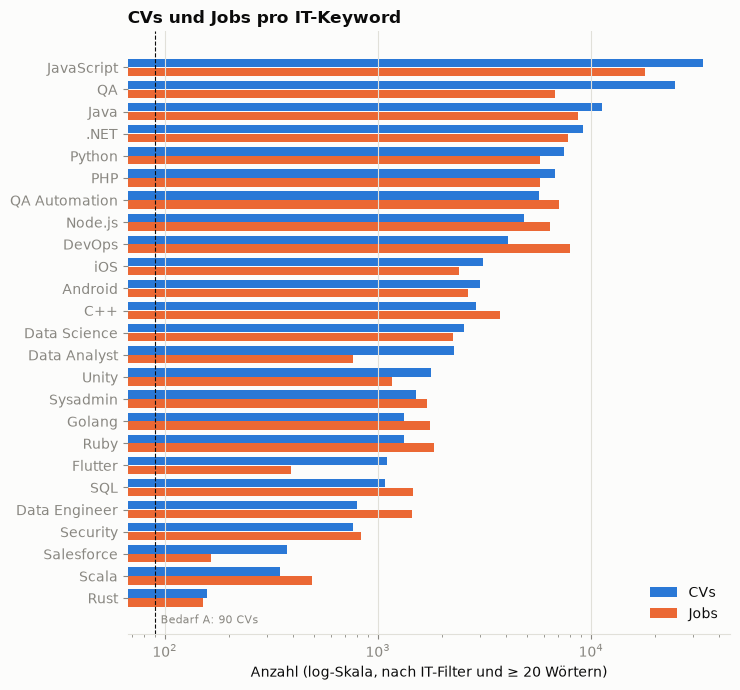

IT-CVs: 131,795 | IT-Jobs: 97,331
Kleinstes Keyword: Rust (158 CVs) / Rust (151 Jobs)


In [3]:
cv_it = cv[cv["Primary Keyword"].isin(IT_KEYWORDS) & (cv["n_words"] >= MIN_WORDS)].copy()
jobs_it = jobs[jobs["Primary Keyword"].isin(IT_KEYWORDS) & (jobs["n_words"] >= MIN_WORDS)].copy()

counts = pd.DataFrame({
    "CVs": cv_it["Primary Keyword"].value_counts(),
    "Jobs": jobs_it["Primary Keyword"].value_counts(),
}).reindex(IT_KEYWORDS).fillna(0).astype(int)

NEED_CV_A = N_PER_RING + TWIN_SOURCES["A"]
order = counts.sort_values("CVs").index

fig, ax = plt.subplots(figsize=(7.5, 7))
y = np.arange(len(order))
ax.barh(y + 0.2, counts.loc[order, "CVs"], height=0.38, color=BLUE, label="CVs")
ax.barh(y - 0.2, counts.loc[order, "Jobs"], height=0.38, color=ORANGE, label="Jobs")
ax.axvline(NEED_CV_A, color=INK, linewidth=0.8, linestyle="--")
ax.annotate(f"Bedarf A: {NEED_CV_A} CVs", (NEED_CV_A, -1), xytext=(4, 0),
            textcoords="offset points", fontsize=8, color=MUTED, va="center")
ax.set_xscale("log")
ax.set_yticks(y, order)
ax.set_xlabel("Anzahl (log-Skala, nach IT-Filter und ≥ 20 Wörtern)")
ax.set_title("CVs und Jobs pro IT-Keyword", loc="left", color=INK, fontweight="bold")
ax.legend(frameon=False, loc="lower right")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

print(f"IT-CVs: {len(cv_it):,} | IT-Jobs: {len(jobs_it):,}")
print(f"Kleinstes Keyword: {counts['CVs'].idxmin()} ({counts['CVs'].min()} CVs) / "
      f"{counts['Jobs'].idxmin()} ({counts['Jobs'].min()} Jobs)")

### Zwischenfazit Mengen

Nach IT-Filter und Qualitätsfilter bleiben 131.795 CVs und 97.331 Jobs in 25 Keywords. Selbst das kleinste Keyword (Rust: 158 CVs / 151 Jobs) deckt den Bedarf des Zielberufs (90 CVs, 20 Jobs). Data Science liegt mit 2.542 CVs und 2.262 Jobs weit darüber.

→ **Die Mengenfrage ist kein Auswahlkriterium.** Ob ein Markt sich eignet, entscheidet sich am Inhalt (Abschnitt 4).

## 3. Screening-Stichprobe: ESCOX und TF-IDF auf denselben Texten

Um den Ausstecher sinnvoll anzusetzen, vergleichen wir alle IT-Keywords miteinander. Pro
Keyword ziehen wir **60 CVs und 20 Jobs** (Seed 42) und schicken sie durch **beide** Methoden:

- **ESCO-Raum:** ESCOX-Labels als binärer Vektor (Dokument × ESCO-URI)
- **TF-IDF-Raum:** `TfidfVectorizer` wie in `eda_proxies.ipynb`, diesmal auf CVs **und** Jobs
  gefittet, damit beide im selben Raum liegen, und mit einem Token-Muster, das Tech-Begriffe wie
  `c#`, `c++` und `.net` erhält (`TFIDF_PARAMS`)

ESCOX läuft auf der CPU mit ca. 0,1 s pro Text – für ~2.000 Texte rund 3–4 Minuten, ein Cache ist
für die EDA nicht nötig.

In [4]:
KEEP = ["id", "doc_type", "Primary Keyword", "text", "n_words", "English Level", "Experience Years", "CV"]

parts = []
for kw in IT_KEYWORDS:
    for doc_type, df, n in [("cv", cv_it, SCREEN_CV_PER_KW), ("job", jobs_it, SCREEN_JOB_PER_KW)]:
        group = df[df["Primary Keyword"] == kw]
        parts.append(group.sample(min(len(group), n), random_state=SEED).assign(doc_type=doc_type))
screen = pd.concat(parts, ignore_index=True).reindex(columns=KEEP)

extractor = EscoExtractor(EscoxConfig(esco_csv=ESCO_PATH))

t0 = time.time()
screen["uris"] = [[s.uri for s in extractor.extract(t)] for t in screen["text"]]
screen["n_labels"] = screen["uris"].str.len()
print(f"ESCOX: {len(screen)} Texte in {time.time() - t0:.0f}s")

screen.groupby("doc_type")["n_labels"].describe().round(1)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

ESCOX: 2000 Texte in 323s


,count,mean,std,min,25%,50%,75%,max
doc_type,,,,,,,,
cv,1500.0,10.0,7.3,0.0,5.0,8.0,13.0,48.0
job,500.0,21.3,11.4,2.0,13.0,19.0,27.0,74.0


In [5]:
# 21 Skills stehen in der offiziellen CSV doppelt (identische Zeilen)
esco = pd.read_csv(ESCO_PATH).fillna("").drop_duplicates("conceptUri")
LANG_SCHEME = "skill-language-groups"
DIGITAL_SCHEME = "6c930acd-c104-4ece-acf7-f44fd7333036"  # ESCO Digital Skills Collection


def label_category(row) -> str:
    if LANG_SCHEME in row["inScheme"]:
        return "Sprache"
    if row["reuseLevel"] == "transversal":
        return "transversal"
    if DIGITAL_SCHEME in row["inScheme"]:
        return "digital"
    return "sonstige"


esco_meta = esco.set_index("conceptUri")[["preferredLabel"]].assign(
    category=esco.apply(label_category, axis=1).values)


def with_meta(df: pd.DataFrame) -> pd.DataFrame:
    out = df.join(esco_meta)
    return out.assign(preferredLabel=out["preferredLabel"].fillna(pd.Series(out.index, index=out.index)),
                      category=out["category"].fillna("sonstige"))

mlb = MultiLabelBinarizer(sparse_output=True)
E = mlb.fit_transform(screen["uris"]).tocsr().astype(float)
uris = mlb.classes_

tfidf = TfidfVectorizer(**TFIDF_PARAMS)
T = tfidf.fit_transform(screen["text"])

is_job = screen["doc_type"].eq("job").to_numpy()
is_cv = ~is_job
kw = screen["Primary Keyword"].to_numpy()

print(f"ESCO-Raum:   {E.shape[0]} Dokumente x {E.shape[1]} verschiedene Labels")
print(f"TF-IDF-Raum: {T.shape[0]} Dokumente x {T.shape[1]} Terme")
print(f"Anteil Texte mit >= {MIN_LABELS} Labels: CVs {(screen.loc[is_cv, 'n_labels'] >= MIN_LABELS).mean():.0%}"
      f" | Jobs {(screen.loc[is_job, 'n_labels'] >= MIN_LABELS).mean():.0%}")

ESCO-Raum:   2000 Dokumente x 3093 verschiedene Labels
TF-IDF-Raum: 2000 Dokumente x 5000 Terme
Anteil Texte mit >= 5 Labels: CVs 76% | Jobs 98%


## 4. Wo setzen wir den Ausstecher an? Nähe der Keywords in beiden Räumen

Für jedes Paar (Job-Keyword, CV-Keyword) berechnen wir den mittleren Score aller Job×CV-Paare:

- **MeritMe:** Recall = |Job-Labels ∩ CV-Labels| / |Job-Labels|
- **Baseline:** TF-IDF-Cosine zwischen Job und CV

Gelesen wird **zeilenweise** („Welche CVs findet ein Job dieses Keywords?“), jede Zeile ist auf
ihr Maximum normiert. Die **Diagonale** ist die Überdeckung von CVs und Jobs desselben Keywords;
helle Felder neben der Diagonale sind Nachbarn (Kandidaten für B), dunkle weit entfernte (C).

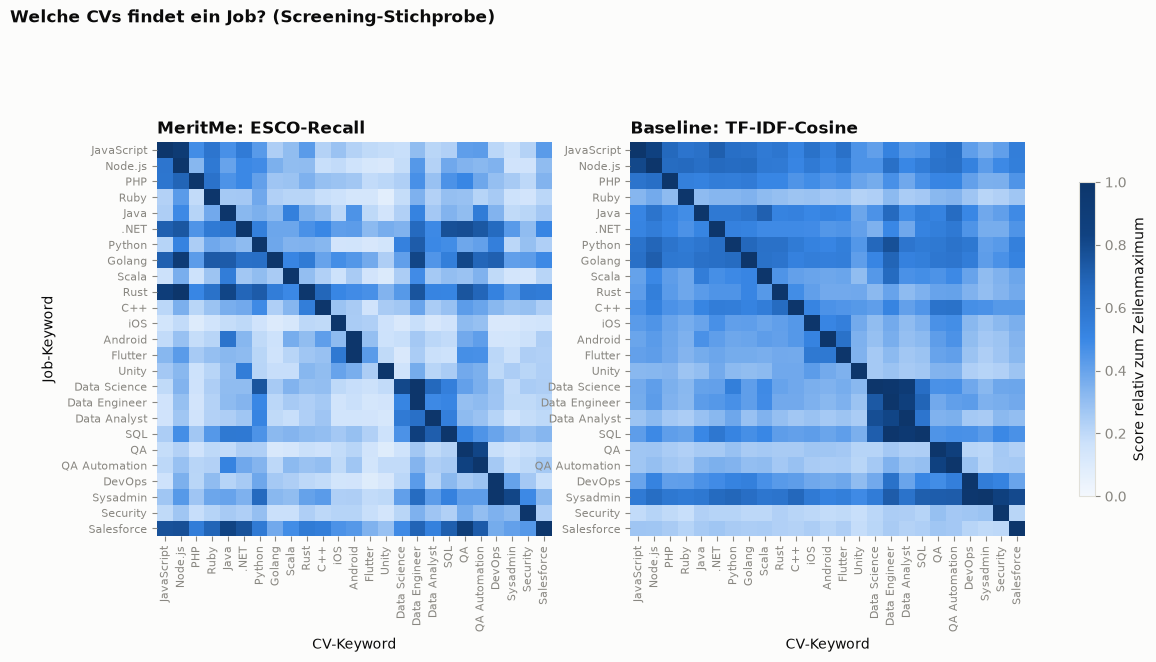

In [6]:
def recall_matrix(E_jobs, E_cvs) -> np.ndarray:
    inter = (E_jobs @ E_cvs.T).toarray()
    n_job = np.asarray(E_jobs.sum(axis=1)).ravel()
    return inter / np.maximum(n_job, 1)[:, None]


def keyword_means(S: np.ndarray) -> pd.DataFrame:
    jk, ck = kw[is_job], kw[is_cv]
    return pd.DataFrame([[S[np.ix_(jk == a, ck == b)].mean() for b in IT_KEYWORDS] for a in IT_KEYWORDS],
                        index=IT_KEYWORDS, columns=IT_KEYWORDS)


S_recall = recall_matrix(E[is_job], E[is_cv])
S_cos = cosine_similarity(T[is_job], T[is_cv])
kw_recall = keyword_means(S_recall)
kw_cos = keyword_means(S_cos)

fig, axes = plt.subplots(1, 2, figsize=(14, 6.8))
for ax, mat, title in [(axes[0], kw_recall, "MeritMe: ESCO-Recall"), (axes[1], kw_cos, "Baseline: TF-IDF-Cosine")]:
    rel = mat.div(mat.max(axis=1), axis=0)
    im = ax.imshow(rel.values, cmap=SEQ_BLUES, vmin=0, vmax=1)
    ax.set_xticks(range(len(IT_KEYWORDS)), IT_KEYWORDS, rotation=90, fontsize=8)
    ax.set_yticks(range(len(IT_KEYWORDS)), IT_KEYWORDS, fontsize=8)
    ax.set_xlabel("CV-Keyword")
    ax.set_ylabel("Job-Keyword" if ax is axes[0] else "")
    ax.set_title(title, loc="left", color=INK, fontweight="bold")
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(False)
fig.colorbar(im, ax=axes, shrink=0.6, label="Score relativ zum Zeilenmaximum")
fig.suptitle("Welche CVs findet ein Job? (Screening-Stichprobe)", x=0.02, ha="left",
             color=INK, fontweight="bold", fontsize=12)
plt.show()

### Ampel pro Keyword

Die Ampel ordnet jedes Keyword als möglichen Zielberuf A ein – **immer in beiden Räumen**, damit
keine der beiden Methoden bevorzugt wird. Sie ist eine Prüfung, keine Auswahlmaschine: A und B gibt
das Team fachlich vor (nächster Abschnitt), die Ampel zeigt, wie gut diese Wahl die Bedingungen erfüllt.

| Kriterium | Messung | Bedingung |
|---|---|---|
| Überdeckung | Diagonale ist Zeilenmaximum (Jobs finden „ihre“ CVs am besten) | in beiden Räumen |
| Trennschärfe | Diagonale / Mittel der übrigen Zeile | **Rangfolge**: geometrisches Mittel beider Räume |
| Nachbar B | Keyword mit bestem mittleren Rang in beiden Räumen | Score relativ zum Kern zwischen 0,5 und 0,9 – in beiden Räumen |
| Fremd C | Keyword mit schlechtestem mittleren Rang in beiden Räumen | Score relativ zum Kern ≤ 0,3 – in beiden Räumen |
| ESCO-Abdeckung | Anteil A-Jobs mit ≥ 5 Labels | ≥ 90 % |
| Menge | CVs und Jobs nach Filter | ≥ 120 CVs, ≥ 20 Jobs |

Sortiert ist nach Trennschärfe; `kandidat` markiert Keywords, die jede Bedingung erfüllen.

In [7]:
rows = []
for a in IT_KEYWORDS:
    r_row, c_row = kw_recall.loc[a], kw_cos.loc[a]
    others = [k for k in IT_KEYWORDS if k != a]
    mean_rank = (r_row[others].rank(ascending=False) + c_row[others].rank(ascending=False)) / 2
    b, c = mean_rank.idxmin(), mean_rank.idxmax()
    a_jobs = screen[is_job & (kw == a)]
    rows.append({
        "keyword": a,
        "n_cv": counts.loc[a, "CVs"],
        "n_job": counts.loc[a, "Jobs"],
        "diag_max": (r_row.idxmax() == a) and (c_row.idxmax() == a),
        "diag_recall": r_row[a],
        "diag_cos": c_row[a],
        "trenn_recall": r_row[a] / r_row[others].mean(),
        "trenn_cos": c_row[a] / c_row[others].mean(),
        "B": b,
        "B_rel_recall": r_row[b] / r_row[a],
        "B_rel_cos": c_row[b] / c_row[a],
        "C": c,
        "C_rel_recall": r_row[c] / r_row[a],
        "C_rel_cos": c_row[c] / c_row[a],
        "job_esco_ok": (a_jobs["n_labels"] >= MIN_LABELS).mean(),
    })
ampel = pd.DataFrame(rows).set_index("keyword")

B_BAND = (0.5, 0.9)   # Rand: deutlich unter dem Kern, aber klar über dem Rest
C_MAX = 0.3           # Außen: weit weg

ampel["B_ok"] = (ampel[["B_rel_recall", "B_rel_cos"]].ge(B_BAND[0]).all(axis=1)
                 & ampel[["B_rel_recall", "B_rel_cos"]].le(B_BAND[1]).all(axis=1))
ampel["C_ok"] = ampel[["C_rel_recall", "C_rel_cos"]].le(C_MAX).all(axis=1)
ampel["kandidat"] = (
    ampel["diag_max"] & ampel["B_ok"] & ampel["C_ok"]
    & (ampel["n_cv"] >= NEED_CV_A) & (ampel["n_job"] >= N_JOBS)
    & (ampel["job_esco_ok"] >= 0.9)
)
# Trennschärfe beider Räume als ein Rang (geometrisches Mittel), damit keine Methode dominiert
ampel["trenn_beide"] = np.sqrt(ampel["trenn_recall"] * ampel["trenn_cos"])
ampel = ampel.sort_values(["kandidat", "trenn_beide"], ascending=False)
ampel.round(2)

,n_cv,n_job,diag_max,diag_recall,diag_cos,trenn_recall,trenn_cos,B,B_rel_recall,B_rel_cos,C,C_rel_recall,C_rel_cos,job_esco_ok,B_ok,C_ok,kandidat,trenn_beide
keyword,,,,,,,,,,,,,,,,,,
QA,24863,6774,True,0.09,0.18,4.76,3.63,QA Automation,0.82,0.86,Unity,0.09,0.22,1.00,True,True,True,4.15
QA Automation,5689,7047,True,0.08,0.17,3.50,3.30,QA,0.83,0.84,Sysadmin,0.18,0.22,1.00,True,True,True,3.40
Data Analyst,2267,767,True,0.07,0.12,3.76,2.85,Data Engineer,0.63,0.82,Unity,0.13,0.25,0.95,True,True,True,3.27
Data Engineer,796,1451,True,0.07,0.11,3.67,2.32,Data Science,0.51,0.74,Unity,0.15,0.28,0.95,True,True,True,2.92
Security,767,830,True,0.04,0.17,4.10,4.50,QA,0.36,0.30,Unity,0.14,0.18,1.00,False,True,False,4.30
Ruby,1321,1834,True,0.10,0.16,4.40,3.43,Node.js,0.43,0.37,Unity,0.07,0.23,1.00,False,True,False,3.88
iOS,3128,2398,True,0.09,0.12,5.85,2.51,Android,0.25,0.51,Sysadmin,0.11,0.28,1.00,False,True,False,3.83
Unity,1774,1165,True,0.05,0.12,3.60,3.19,iOS,0.40,0.42,Data Science,0.16,0.26,1.00,False,True,False,3.39
Android,3007,2651,True,0.08,0.13,3.76,2.58,Java,0.61,0.46,Sysadmin,0.14,0.26,0.95,False,True,False,3.11


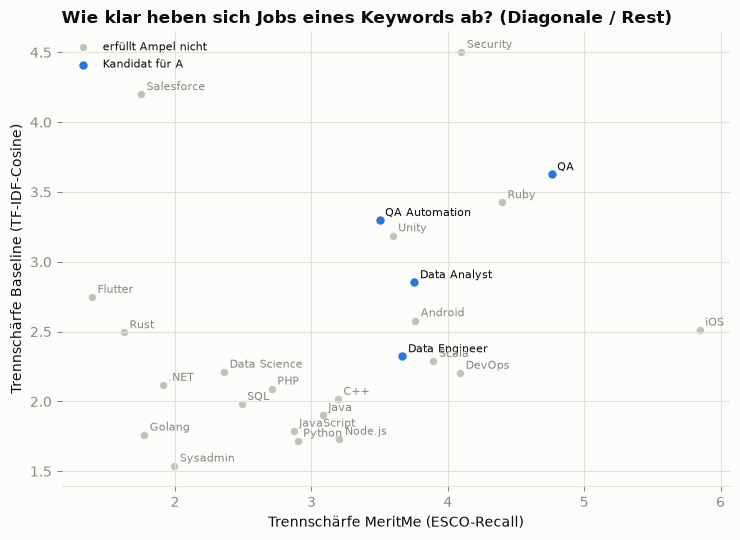

In [8]:
fig, ax = plt.subplots(figsize=(7.5, 5.5))
cand = ampel["kandidat"]
ax.scatter(ampel.loc[~cand, "trenn_recall"], ampel.loc[~cand, "trenn_cos"], s=40,
           color=OTHER_GREY, edgecolor=SURFACE, linewidth=1, label="erfüllt Ampel nicht")
ax.scatter(ampel.loc[cand, "trenn_recall"], ampel.loc[cand, "trenn_cos"], s=50,
           color=BLUE, edgecolor=SURFACE, linewidth=1, label="Kandidat für A")
for name, row in ampel.iterrows():
    ax.annotate(name, (row["trenn_recall"], row["trenn_cos"]), xytext=(4, 3),
                textcoords="offset points", fontsize=8, color=INK if row["kandidat"] else MUTED)
ax.set_xlabel("Trennschärfe MeritMe (ESCO-Recall)")
ax.set_ylabel("Trennschärfe Baseline (TF-IDF-Cosine)")
ax.set_title("Wie klar heben sich Jobs eines Keywords ab? (Diagonale / Rest)", loc="left",
             color=INK, fontweight="bold")
ax.legend(frameon=False, fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

### Entscheidung: Zielberuf A, Nachbar B, Fremd C

A und B gibt das Team fachlich vor: **Data-Science-Stellen** als Zielberuf, **Python-Entwickler:innen**
als Rand – verwandt über Python- und Software-Kenntnisse, aber mit anderer Kernrolle. Die Vorgabe
nutzt nur das `Primary Keyword` und ist damit weiterhin methodenneutral. C wird regelbasiert
bestimmt: das Keyword, dessen CVs für A-Jobs in beiden Räumen im Mittel am schlechtesten ranken.

**Ergebnis der Prüfung (Profil oben):**

| Ring | Keyword | ESCO-Recall rel. zum Kern | TF-IDF-Cosine rel. zum Kern |
|---|---|---|---|
| A | Data Science | 1,00 | 1,00 |
| B | Python | **0,93** | 0,55 |
| C | PHP | 0,20 | 0,35 |

- **Im TF-IDF-Raum** passt die Vorgabe gut: Python liegt mitten im Rand-Band, PHP am unteren Ende. Kein IT-Keyword fällt für Data-Science-Jobs unter 0,3. Allgemeines IT-Vokabular hält TF-IDF für alle IT-CVs über etwa 0,33, also ist PHP das fernste verfügbare Keyword.
- **Im ESCO-Raum** sind Python-CVs für Data-Science-Jobs **fast so gut wie Data-Science-CVs** (0,93), Data-Engineer-CVs sogar besser (1,24). Data Science erfüllt deshalb schon die Bedingung „Diagonale ist Zeilenmaximum“ nicht. Die geteilten Labels sind vor allem *Python (computer programming)* und *SQL*. Die Data-Science-spezifischen Labels gibt es zwar (Abschnitt 6), sie kommen in CVs aber selten vor.

→ Der Markt ist fachlich sinnvoll und im TF-IDF-Raum sauber gestaffelt. **MeritMe sieht Kern und Rand dagegen als fast gleich.** Das ist selbst ein Befund über ESCO und kein Grund, die Vorgabe zu ändern: Der Rankingtest misst Rangabstände zwischen Zwillingen, nicht, ob eine Methode die Ringe trennt. Es verschärft aber das Gleichstandsproblem (Abschnitt 8).

Falls ein Rand gewünscht ist, der in beiden Räumen im Band liegt: **SQL** (ca. 0,67 / 0,64).

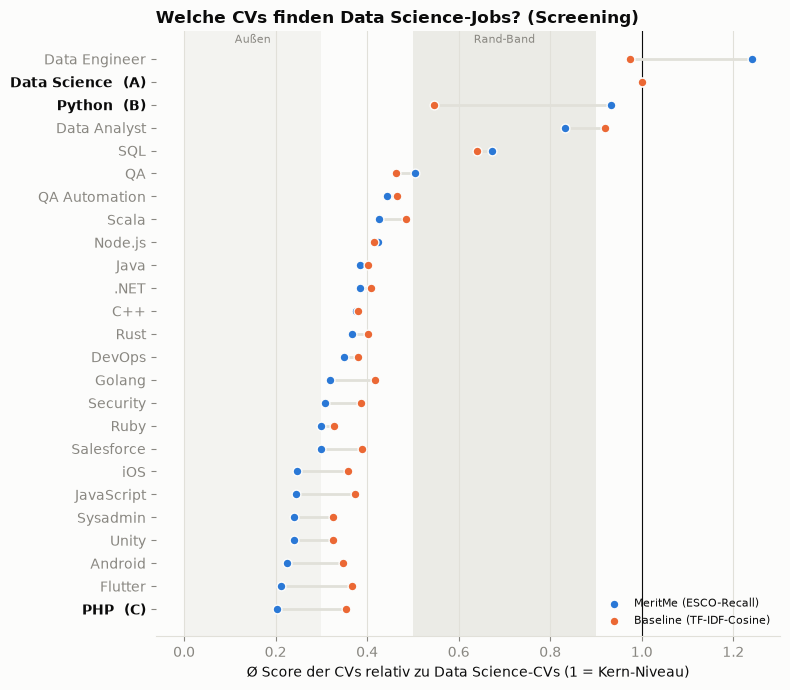

,ESCO-Recall,TF-IDF-Cosine,Ø Labels pro CV,Ring
Data Science,1.00,1.00,11.20,A
Python,0.93,0.55,9.95,B
PHP,0.20,0.35,8.13,C


In [9]:
A, B = "Data Science", "Python"   # fachliche Vorgabe des Teams
C = ampel.loc[A, "C"]              # regelbasiert: schlechtester mittlerer Rang für A-Jobs in beiden Räumen
RINGS = {"A": A, "B": B, "C": C}

profile = pd.DataFrame({
    "ESCO-Recall": kw_recall.loc[A] / kw_recall.loc[A, A],
    "TF-IDF-Cosine": kw_cos.loc[A] / kw_cos.loc[A, A],
    "Ø Labels pro CV": screen[is_cv].groupby("Primary Keyword")["n_labels"].mean(),
})
profile["Ring"] = profile.index.map({v: r for r, v in RINGS.items()}).fillna("")
profile = profile.sort_values("ESCO-Recall")

fig, ax = plt.subplots(figsize=(8, 7))
y = np.arange(len(profile))
ax.axvspan(*B_BAND, color=GRID, alpha=0.6, linewidth=0)
ax.axvspan(0, C_MAX, color=GRID, alpha=0.3, linewidth=0)
ax.axvline(1, color=INK, linewidth=0.8)
ax.hlines(y, profile["ESCO-Recall"], profile["TF-IDF-Cosine"], color=GRID, linewidth=2)
ax.scatter(profile["ESCO-Recall"], y, s=40, color=BLUE, edgecolor=SURFACE, linewidth=1,
           label="MeritMe (ESCO-Recall)", zorder=3)
ax.scatter(profile["TF-IDF-Cosine"], y, s=40, color=ORANGE, edgecolor=SURFACE, linewidth=1,
           label="Baseline (TF-IDF-Cosine)", zorder=3)
ax.set_yticks(y, [f"{k_}  ({r})" if r else k_ for k_, r in zip(profile.index, profile["Ring"])])
for tick, r in zip(ax.get_yticklabels(), profile["Ring"]):
    if r:
        tick.set_color(INK)
        tick.set_fontweight("bold")
ax.annotate("Rand-Band", (np.mean(B_BAND), len(profile) - 0.3), ha="center", fontsize=8, color=MUTED)
ax.annotate("Außen", (C_MAX / 2, len(profile) - 0.3), ha="center", fontsize=8, color=MUTED)
ax.set_xlabel(f"Ø Score der CVs relativ zu {A}-CVs (1 = Kern-Niveau)")
ax.set_title(f"Welche CVs finden {A}-Jobs? (Screening)", loc="left", color=INK, fontweight="bold")
ax.legend(frameon=False, fontsize=8, loc="lower right")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

profile.loc[[A, B, C]].round(2)

## 5. PCA & Clustering: Bilden beide Räume die Rollen ab?

Wie in `eda_proxies.ipynb` (Abschnitt 3) clustern wir mit KMeans (k = Anzahl Keywords) und
messen per ARI die Übereinstimmung mit dem `Primary Keyword` – diesmal in **beiden** Räumen und
für CVs **und** Jobs gemeinsam. Zusätzlich prüfen wir, ob unsere Textdefinition (ohne
`Looking For`) das TF-IDF-Ergebnis gegenüber Aylas Variante (Spalte `CV`) verändert.

**Achtung:** Abstände im 2D-PCA-Plot sind eine Projektion – nur zur Anschauung. Gerechnet wird
immer im vollen Raum.

In [10]:
k = len(IT_KEYWORDS)
E_norm = normalize(E)  # L2, damit lange Texte mit vielen Labels nicht dominieren


def kmeans_ari(X, labels) -> float:
    km = KMeans(n_clusters=k, random_state=SEED, n_init=10)
    return adjusted_rand_score(labels, km.fit_predict(X))


cv_rows = screen[is_cv]
T_cv_ayla = TfidfVectorizer(**TFIDF_PARAMS).fit_transform(cv_rows["CV"])

ari = pd.DataFrame([
    {"Raum": "TF-IDF", "Dokumente": "CVs + Jobs", "Text": "neu", "ARI": kmeans_ari(T, kw)},
    {"Raum": "ESCO", "Dokumente": "CVs + Jobs", "Text": "neu", "ARI": kmeans_ari(E_norm, kw)},
    {"Raum": "TF-IDF", "Dokumente": "nur CVs", "Text": "neu", "ARI": kmeans_ari(T[is_cv], kw[is_cv])},
    {"Raum": "TF-IDF", "Dokumente": "nur CVs", "Text": "Spalte CV (Ayla)", "ARI": kmeans_ari(T_cv_ayla, kw[is_cv])},
    {"Raum": "ESCO", "Dokumente": "nur CVs", "Text": "neu", "ARI": kmeans_ari(E_norm[is_cv], kw[is_cv])},
])
ari.round(3)

,Raum,Dokumente,Text,ARI
0,TF-IDF,CVs + Jobs,neu,0.341
1,ESCO,CVs + Jobs,neu,0.186
2,TF-IDF,nur CVs,neu,0.369
3,TF-IDF,nur CVs,Spalte CV (Ayla),0.302
4,ESCO,nur CVs,neu,0.178


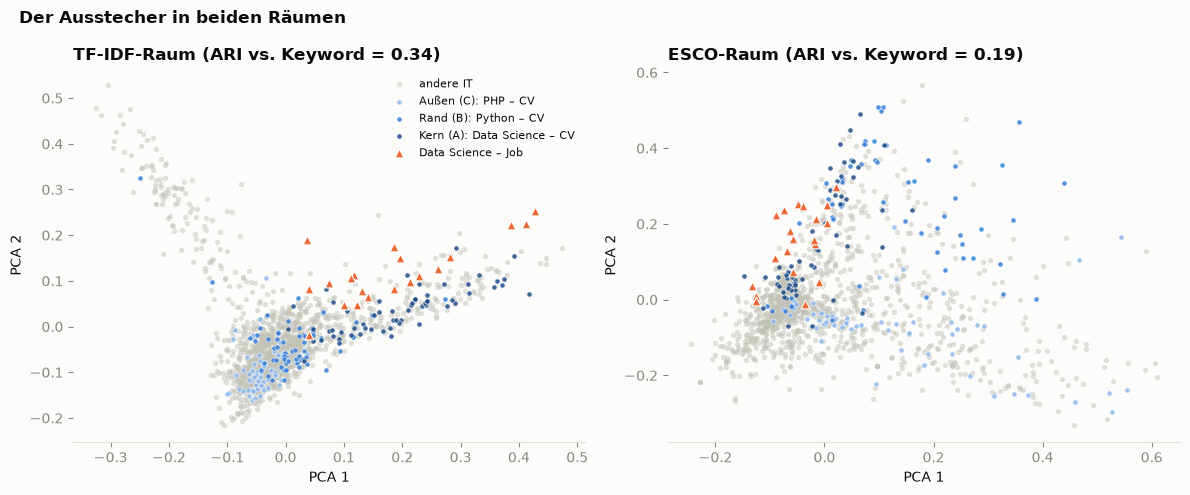

In [11]:
coords = {
    "TF-IDF": PCA(n_components=2, random_state=SEED).fit_transform(T.toarray()),
    "ESCO": PCA(n_components=2, random_state=SEED).fit_transform(E_norm.toarray()),
}
ring_of = pd.Series(kw).map({v: r for r, v in RINGS.items()}).to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (space, xy) in zip(axes, coords.items()):
    rest = pd.isna(ring_of)
    ax.scatter(xy[rest & is_cv, 0], xy[rest & is_cv, 1], s=8, color=OTHER_GREY, alpha=0.4, label="andere IT")
    for r in ["C", "B", "A"]:
        m = ring_of == r
        ax.scatter(xy[m & is_cv, 0], xy[m & is_cv, 1], s=14, color=RING_COLORS[r], alpha=0.8,
                   edgecolor=SURFACE, linewidth=0.5, label=f"{RING_NAMES[r]}: {RINGS[r]} – CV")
    m = ring_of == "A"
    ax.scatter(xy[m & is_job, 0], xy[m & is_job, 1], s=40, marker="^", color=ORANGE,
               edgecolor=SURFACE, linewidth=0.8, label=f"{A} – Job")
    ari_val = ari.query("Raum == @space and Dokumente == 'CVs + Jobs'")["ARI"].iloc[0]
    ax.set_title(f"{space}-Raum (ARI vs. Keyword = {ari_val:.2f})", loc="left", color=INK, fontweight="bold")
    ax.set_xlabel("PCA 1")
    ax.set_ylabel("PCA 2")
    ax.grid(visible=False)
axes[0].legend(frameon=False, fontsize=8, loc="best")
fig.suptitle("Der Ausstecher in beiden Räumen", x=0.02, ha="left", color=INK, fontweight="bold", fontsize=12)
plt.tight_layout()
plt.show()

### Zwischenfazit PCA & Clustering

**TF-IDF bildet die Rollen deutlich besser ab als ESCO:** ARI 0,34 gegenüber 0,19 (CVs + Jobs, 25 IT-Keywords). Im TF-IDF-Raum bilden sich erkennbare Gruppen (z. B. QA, Data), im ESCO-Raum liegen alle Keywords in einer Wolke. Auf Rollenebene ist der ESCO-Raum also gröber. Das passt zur geringen Zahl an Labels pro Text und zu den ESCO-Lücken (Abschnitt 6).

**Textdefinition:** Ohne `Looking For` steigt der ARI der CVs im TF-IDF-Raum von 0,30 auf 0,37. Der Effekt ist kleiner als mit dem Standard-Token-Muster (dort 0,29 → 0,45), zeigt aber in dieselbe Richtung und stützt die Entscheidung aus Abschnitt 1. (Aylas 0,49 ist nicht direkt vergleichbar: 8 Keywords inkl. Design und Marketing lassen sich leichter trennen als 25 IT-Keywords.)

**Keine Aussage über Fairness:** Dass ESCO Rollen schlechter trennt, ist für MeritMe kein Problem an sich, denn Ziel ist ein stilunabhängiger Score, keine Rollenerkennung.

## 6. Welche ESCO-Labels matchen gut?

Für ESCO-Labels gibt es keine Ground Truth. Wir messen drei Eigenschaften:

1. **Rauschen:** Labels, die über alle IT-Keywords gleich häufig vorkommen, tragen nichts zur
   Unterscheidung bei (Kandidaten: Sprach-Skills, transversale Soft Skills, ESCOX-Fehltreffer).
2. **Spezifität & Übereinstimmung:** Labels, die in A deutlich häufiger sind als im Rest der IT
   (Lift) **und** sowohl in A-CVs als auch in A-Jobs vorkommen – das sind die Labels, über die der
   Recall-Score in unserem Markt tatsächlich entscheidet.
3. **Lücken:** Begriffe, die A-Jobs prägen, für die ESCO aber gar kein Label hat.

Rausch-Labels werden hier nur **dokumentiert** – ob sie im Matching gefiltert oder
heruntergewichtet werden, entscheidet die Matching-Entwicklung in Sprint 3.

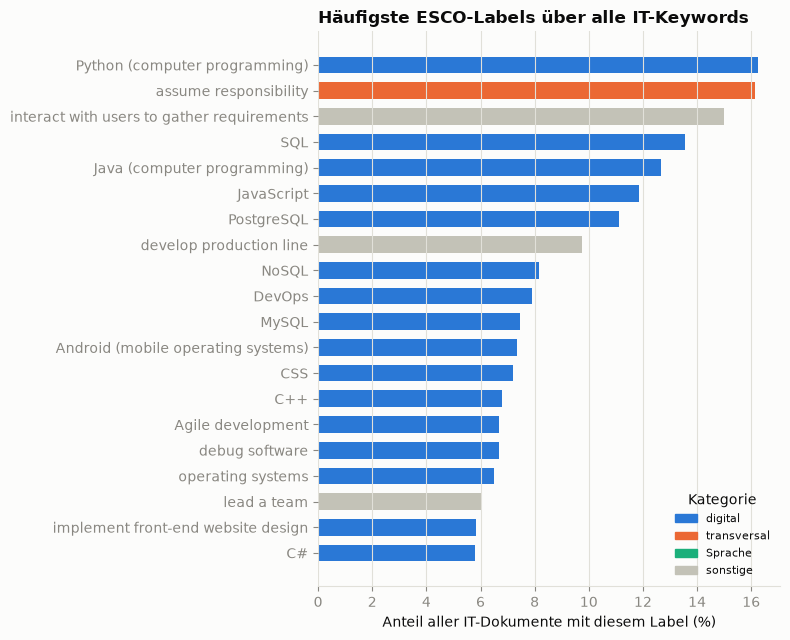

,preferredLabel,category,CVs,Jobs,n_keywords_10pct
http://data.europa.eu/esco/skill/ccd0a1d9-afda-43d9-b901-96344886e14d,Python (computer programming),digital,0.146,0.212,12
http://data.europa.eu/esco/skill/199f7919-5114-41b6-b6a5-41e0e4896ec1,assume responsibility,transversal,0.067,0.446,23
http://data.europa.eu/esco/skill/a8797f21-1af0-4c5e-98ca-bf1442929363,interact with users to gather requirements,sonstige,0.044,0.468,21
http://data.europa.eu/esco/skill/598de5b0-5b58-4ea7-8058-a4bc4d18c742,SQL,digital,0.126,0.164,14
http://data.europa.eu/esco/skill/19a8293b-8e95-4de3-983f-77484079c389,Java (computer programming),digital,0.119,0.148,6
http://data.europa.eu/esco/skill/3cd569a2-4f88-4c1e-9995-8dce8c5e51a7,JavaScript,digital,0.119,0.116,9
http://data.europa.eu/esco/skill/a8d07b5a-c1a1-42c6-9d53-db9c7a2ca996,PostgreSQL,digital,0.113,0.106,9
http://data.europa.eu/esco/skill/bb40da1a-232f-4ba1-a9f5-5283a4fb7a7a,develop production line,sonstige,0.069,0.182,10
http://data.europa.eu/esco/skill/76ef6ed3-1658-4a1a-9593-204d799c6d0c,NoSQL,digital,0.073,0.108,8
http://data.europa.eu/esco/skill/f0de4973-0a70-4644-8fd4-3a97080476f4,DevOps,digital,0.073,0.096,4


In [12]:
doc_freq = pd.DataFrame({
    "CVs": np.asarray(E[is_cv].mean(axis=0)).ravel(),
    "Jobs": np.asarray(E[is_job].mean(axis=0)).ravel(),
}, index=uris).pipe(with_meta)
doc_freq["alle"] = np.asarray(E.mean(axis=0)).ravel()
# Verbreitung: in wie vielen der Keywords kommt das Label in >= 10 % der Dokumente vor?
kw_share = pd.DataFrame({k_: np.asarray(E[kw == k_].mean(axis=0)).ravel() for k_ in IT_KEYWORDS}, index=uris)
doc_freq["n_keywords_10pct"] = (kw_share >= 0.10).sum(axis=1)

top = doc_freq.sort_values("alle", ascending=False).head(20)

fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh(top["preferredLabel"][::-1], top["alle"][::-1] * 100,
        color=[CAT_COLORS[c] for c in top["category"][::-1]], height=0.65)
ax.set_xlabel("Anteil aller IT-Dokumente mit diesem Label (%)")
ax.set_title("Häufigste ESCO-Labels über alle IT-Keywords", loc="left", color=INK, fontweight="bold")
ax.legend(handles=[Patch(color=c, label=k_) for k_, c in CAT_COLORS.items()],
          frameon=False, fontsize=8, loc="lower right", title="Kategorie")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

top[["preferredLabel", "category", "CVs", "Jobs", "n_keywords_10pct"]].round(3)

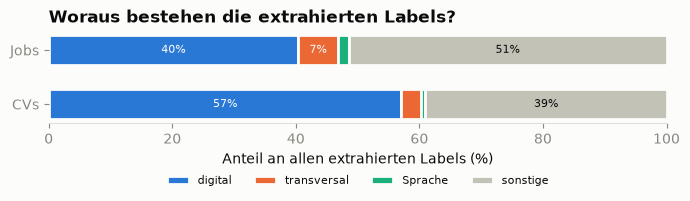

,digital,transversal,Sprache,sonstige
,,,,
CVs,0.571,0.033,0.006,0.390
Jobs,0.403,0.065,0.017,0.515


In [13]:
label_cat = esco_meta["category"].reindex(uris).fillna("sonstige").to_numpy()
cat_share = []
for doc_type, mask in [("CVs", is_cv), ("Jobs", is_job)]:
    sub = E[mask]
    total = sub.sum()
    cat_share.append({c: sub[:, label_cat == c].sum() / total for c in CAT_COLORS} | {"": doc_type})
cat_share = pd.DataFrame(cat_share).set_index("")

fig, ax = plt.subplots(figsize=(7, 2.6))
left = np.zeros(len(cat_share))
for cat, color in CAT_COLORS.items():
    vals = cat_share[cat].to_numpy() * 100
    ax.barh(cat_share.index, vals, left=left, color=color, height=0.55, edgecolor=SURFACE, linewidth=2, label=cat)
    for i, v in enumerate(vals):
        if v >= 4:
            ax.text(left[i] + v / 2, i, f"{v:.0f}%", ha="center", va="center", fontsize=8, color=SURFACE if cat != "sonstige" else INK)
    left += vals
ax.set_xlim(0, 100)
ax.set_xlabel("Anteil an allen extrahierten Labels (%)")
ax.set_title("Woraus bestehen die extrahierten Labels?", loc="left", color=INK, fontweight="bold")
ax.legend(frameon=False, fontsize=8, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.45))
ax.grid(False)
plt.tight_layout()
plt.show()

cat_share.round(3)

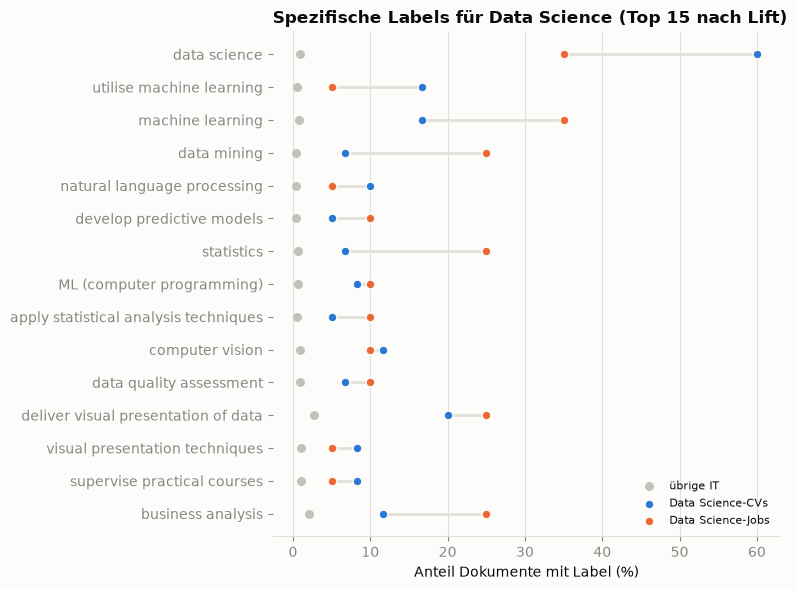

,preferredLabel,category,A_CVs,A_Jobs,Rest_IT,lift
http://data.europa.eu/esco/skill/edebd83d-35f6-4ed5-a940-6c203d178c01,data science,digital,0.60,0.35,0.01,60.71
http://data.europa.eu/esco/skill/8369c2d6-c100-4cf6-bd83-9668d8678433,utilise machine learning,digital,0.17,0.05,0.00,29.33
http://data.europa.eu/esco/skill/3a2d5b45-56e4-4f5a-a55a-4a4a65afdc43,machine learning,digital,0.17,0.35,0.01,27.20
http://data.europa.eu/esco/skill/25f0ea33-b4a2-4f31-b7b4-7d20e827b180,data mining,digital,0.07,0.25,0.00,27.00
http://data.europa.eu/esco/skill/fff0e2cd-d0bd-4b02-9daf-158b79d9688a,natural language processing,digital,0.10,0.05,0.00,21.00
http://data.europa.eu/esco/skill/e2887d71-8ff4-4188-9926-22bdaefa7713,develop predictive models,sonstige,0.05,0.10,0.00,17.14
http://data.europa.eu/esco/skill/7ee4c2ea-b349-4bd2-81a3-ec31475d4833,statistics,sonstige,0.07,0.25,0.01,16.62
http://data.europa.eu/esco/skill/a4d336a6-9ffd-402a-91cc-f359716ba4e0,ML (computer programming),digital,0.08,0.10,0.01,14.00
http://data.europa.eu/esco/skill/382c11ed-20d5-4ae7-b60e-15fec527fa6c,apply statistical analysis techniques,digital,0.05,0.10,0.00,13.33
http://data.europa.eu/esco/skill/7b0d5000-00da-4864-b776-6de49a87a669,computer vision,digital,0.12,0.10,0.01,12.00


In [14]:
in_a = kw == A
share_a_cv = np.asarray(E[is_cv & in_a].mean(axis=0)).ravel()
share_a_job = np.asarray(E[is_job & in_a].mean(axis=0)).ravel()
share_a = np.asarray(E[in_a].mean(axis=0)).ravel()
share_rest = np.asarray(E[~in_a].mean(axis=0)).ravel()

spec = pd.DataFrame({
    "A_CVs": share_a_cv, "A_Jobs": share_a_job, "A": share_a, "Rest_IT": share_rest,
}, index=uris).pipe(with_meta)
spec["lift"] = spec["A"] / np.maximum(spec["Rest_IT"], 1 / (~in_a).sum())
spec = spec[(spec["A_CVs"] >= 0.05) & (spec["A_Jobs"] >= 0.05)]  # muss auf beiden Seiten vorkommen
top_spec = spec.sort_values("lift", ascending=False).head(15)

fig, ax = plt.subplots(figsize=(8, 6))
y = np.arange(len(top_spec))[::-1]
ax.hlines(y, top_spec["A_CVs"] * 100, top_spec["A_Jobs"] * 100, color=GRID, linewidth=2)
ax.scatter(top_spec["Rest_IT"] * 100, y, s=30, color=OTHER_GREY, label="übrige IT", zorder=3)
ax.scatter(top_spec["A_CVs"] * 100, y, s=40, color=BLUE, edgecolor=SURFACE, linewidth=1, label=f"{A}-CVs", zorder=3)
ax.scatter(top_spec["A_Jobs"] * 100, y, s=40, color=ORANGE, edgecolor=SURFACE, linewidth=1, label=f"{A}-Jobs", zorder=3)
ax.set_yticks(y, top_spec["preferredLabel"])
ax.set_xlabel("Anteil Dokumente mit Label (%)")
ax.set_title(f"Spezifische Labels für {A} (Top 15 nach Lift)", loc="left", color=INK, fontweight="bold")
ax.legend(frameon=False, fontsize=8, loc="lower right")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

top_spec[["preferredLabel", "category", "A_CVs", "A_Jobs", "Rest_IT", "lift"]].round(2)

### ESCO-Lücken: Was prägt A-Jobs, kennt ESCO aber nicht?

Wir nehmen die Terme, die A-Jobs im TF-IDF-Raum am stärksten vom Rest der IT-Jobs abheben, und
prüfen, ob es ein ESCO-Label (`preferredLabel` oder `altLabels`) gibt, das genau diesem Begriff
entspricht (exakt oder als „Begriff (…)“, z. B. „Python (computer programming)“).

**Caveat:** grober Abgleich auf Einzelwörtern – Mehrwort-Begriffe und Abkürzungen fallen durch.

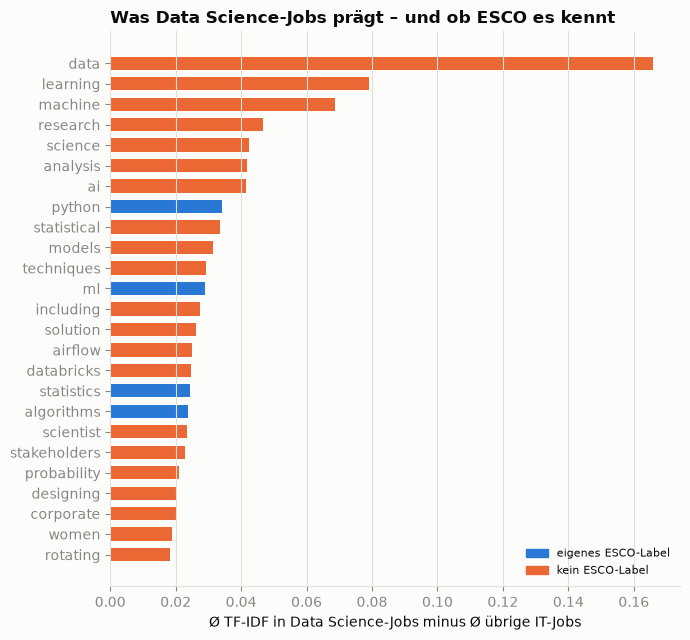

Ohne ESCO-Label: data, learning, machine, research, science, analysis, ai, statistical, models, techniques, including, solution, airflow, databricks, scientist, stakeholders, probability, designing, corporate, women, rotating


In [15]:
esco_label_set = set()
for col in ["preferredLabel", "altLabels"]:
    for value in esco[col]:
        for phrase in str(value).split("\n"):
            phrase = phrase.strip().lower()
            if phrase:
                esco_label_set.add(phrase)
                esco_label_set.add(phrase.split(" (")[0])

terms = np.array(tfidf.get_feature_names_out())
mean_a_jobs = np.asarray(T[is_job & in_a].mean(axis=0)).ravel()
mean_rest_jobs = np.asarray(T[is_job & ~in_a].mean(axis=0)).ravel()
distinct = pd.DataFrame({"term": terms, "delta": mean_a_jobs - mean_rest_jobs})
distinct = distinct.sort_values("delta", ascending=False).head(25)
distinct["in_esco"] = distinct["term"].isin(esco_label_set)

fig, ax = plt.subplots(figsize=(7, 6.5))
ax.barh(distinct["term"][::-1], distinct["delta"][::-1],
        color=[BLUE if m else ORANGE for m in distinct["in_esco"][::-1]], height=0.65)
ax.set_xlabel(f"Ø TF-IDF in {A}-Jobs minus Ø übrige IT-Jobs")
ax.set_title(f"Was {A}-Jobs prägt – und ob ESCO es kennt", loc="left", color=INK, fontweight="bold")
ax.legend(handles=[Patch(color=BLUE, label="eigenes ESCO-Label"), Patch(color=ORANGE, label="kein ESCO-Label")],
          frameon=False, fontsize=8, loc="lower right")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

print(f"Ohne ESCO-Label: {', '.join(distinct.loc[~distinct['in_esco'], 'term'])}")

### Nebenfrage: Sprach-Labels und Englischniveau

Backlog (07.10.2026): *Wie oft extrahiert ESCOX Sprach-Skills aus dem Freitext und hängt das mit
dem Englischniveau zusammen?* Wenn ja, wäre das ein Proxy, der über Sprach-Labels in den
ESCO-Raum gelangt.

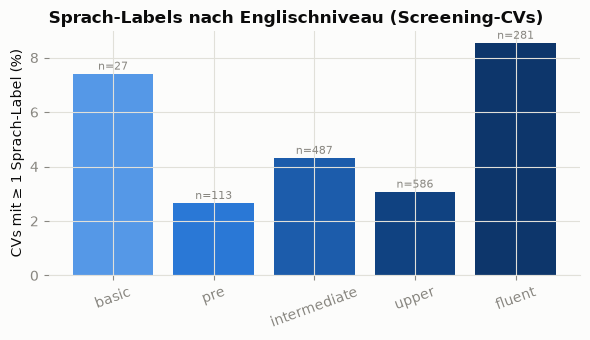

Anteil mit Sprach-Label: CVs 5% | Jobs 30%


,mean,count
English Level,,
no_english,NaN,NaN
basic,0.074,27.0
pre,0.027,113.0
intermediate,0.043,487.0
upper,0.031,586.0
fluent,0.085,281.0


In [16]:
level_order = ["no_english", "basic", "pre", "intermediate", "upper", "fluent"]
has_lang = np.asarray(E[:, label_cat == "Sprache"].sum(axis=1)).ravel() > 0
screen["has_lang_label"] = has_lang

lang_by_level = (screen[is_cv].groupby("English Level")["has_lang_label"]
                 .agg(["mean", "count"]).reindex(level_order))

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(level_order, lang_by_level["mean"] * 100, color=BLUE_ORDINAL[:len(level_order)])
for i, n in enumerate(lang_by_level["count"]):
    if pd.notna(n):
        ax.annotate(f"n={int(n)}", (i, lang_by_level['mean'].iloc[i] * 100), xytext=(0, 3),
                    textcoords="offset points", ha="center", fontsize=8, color=MUTED)
ax.set_ylabel("CVs mit ≥ 1 Sprach-Label (%)")
ax.set_title("Sprach-Labels nach Englischniveau (Screening-CVs)", loc="left", color=INK, fontweight="bold")
ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

print(f"Anteil mit Sprach-Label: CVs {has_lang[is_cv].mean():.0%} | Jobs {has_lang[is_job].mean():.0%}")
lang_by_level.round(3)

### Zwischenfazit ESCO-Labels

**Rauschen sitzt vor allem in den Jobs.** Die häufigsten Nicht-Tech-Labels stammen fast nur aus Ausschreibungen: *assume responsibility* (45 % der Jobs, 7 % der CVs) und *interact with users to gather requirements* (47 % / 4 %). Dazu kommt der ESCOX-Fehltreffer *develop production line* (18 % / 7 %). Bei Jobs ist die Hälfte der Labels weder digital noch transversal („sonstige“ 51 %), bei CVs sind es 39 %. Diese Labels blähen beim Recall den Nenner auf, ohne dass ein CV sie je liefern kann.

**Für Data Science matchen** (häufig in A, selten im Rest der IT): *data science* (60 % der CVs / 35 % der Jobs), *machine learning* (17 % / 35 %), *data mining* (7 % / 25 %), *statistics* (7 % / 25 %), *deliver visual presentation of data* (20 % / 25 %), *computer vision* (12 % / 10 %). ESCO deckt den Kern der Rolle also ab, aber die Labels sind **in CVs selten**. Daher erreichen Python-CVs im ESCO-Raum fast Kern-Niveau, denn sie teilen die häufigen Labels *Python* und *SQL*. Vereinzelt tauchen fachfremde Treffer auf (*supervise practical courses*).

**ESCO-Lücken bei Data Science:** airflow, databricks, ai, probability. Werkzeuge und KI-Begriffe haben kein eigenes Label. (Der Einzelwort-Abgleich meldet auch „machine“ und „learning“, obwohl es *machine learning* als Label gibt. Er ist also nur grob.)

**Sprach-Labels (Nebenfrage):** Sie kommen in 30 % der Jobs vor („English upper-intermediate“), aber nur in 5 % der CVs, und hängen bei CVs nicht monoton mit dem Englischniveau zusammen (2,7–8,5 %). Sie sind also kein Demografie-Proxy, sondern ein **gleichförmiger Abzug für alle**. → Im Matching nicht oder nur gering gewichten (Entscheidung Sprint 3).

## 7. Proxy-Leck im ESCO-Raum?

Der MeritMe-Score ist ein Recall: Ein CV mit **mehr** Labels trifft automatisch mehr Job-Labels.
`eda_proxies.ipynb` hat gezeigt, dass die CV-Länge monoton mit dem Englischniveau steigt. Wenn die
Anzahl der Labels mit der Textlänge wächst, kann Länge – und damit indirekt Englischniveau
oder Erfahrung – über die *Menge* der Labels in den Score einsickern, auch wenn jedes einzelne
Label neutral ist. Erfahrung fließt bewusst nicht in MeritMe ein; hier prüfen wir, ob sie durch
die Hintertür kommt.

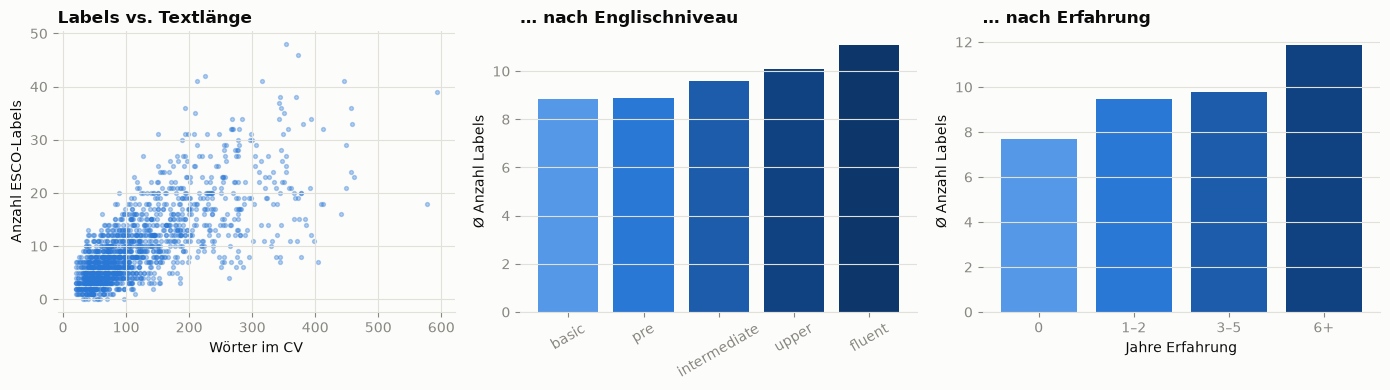

,Größe,Proxy,Spearman ρ,p
0,Anzahl Labels,Textlänge,0.732,0.000
1,Anzahl Labels,Englischniveau,0.081,0.002
2,Anzahl Labels,Erfahrung,0.187,0.000
3,Anteil transversal+Sprache,Textlänge,0.234,0.000
4,Anteil transversal+Sprache,Englischniveau,0.034,0.189
5,Anteil transversal+Sprache,Erfahrung,-0.041,0.109


In [17]:
cvs = screen[is_cv].copy()
cvs["transversal_share"] = (np.asarray(E[is_cv][:, np.isin(label_cat, ["transversal", "Sprache"])].sum(axis=1)).ravel()
                            / np.maximum(cvs["n_labels"], 1))
cvs["exp_bucket"] = pd.cut(cvs["Experience Years"], [-0.1, 0.5, 2, 5, 11], labels=["0", "1–2", "3–5", "6+"])
cvs["level_num"] = cvs["English Level"].map({lvl: i for i, lvl in enumerate(level_order)})

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].scatter(cvs["n_words"], cvs["n_labels"], s=8, alpha=0.35, color=BLUE)
axes[0].set_xlabel("Wörter im CV")
axes[0].set_ylabel("Anzahl ESCO-Labels")
axes[0].set_title("Labels vs. Textlänge", loc="left", color=INK, fontweight="bold")

by_level = cvs.groupby("English Level")["n_labels"].mean().reindex(level_order)
axes[1].bar(level_order, by_level.values, color=BLUE_ORDINAL[:len(level_order)])
axes[1].set_ylabel("Ø Anzahl Labels")
axes[1].set_title("… nach Englischniveau", loc="left", color=INK, fontweight="bold")
axes[1].tick_params(axis="x", rotation=30)
axes[1].grid(axis="x", visible=False)

by_exp = cvs.groupby("exp_bucket", observed=False)["n_labels"].mean()
axes[2].bar(by_exp.index.astype(str), by_exp.values, color=BLUE_ORDINAL[1:5])
axes[2].set_xlabel("Jahre Erfahrung")
axes[2].set_ylabel("Ø Anzahl Labels")
axes[2].set_title("… nach Erfahrung", loc="left", color=INK, fontweight="bold")
axes[2].grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

rows = []
for target, label in [("n_labels", "Anzahl Labels"), ("transversal_share", "Anteil transversal+Sprache")]:
    for proxy, plabel in [("n_words", "Textlänge"), ("level_num", "Englischniveau"), ("Experience Years", "Erfahrung")]:
        sub = cvs[[target, proxy]].dropna()
        rho, p = spearmanr(sub[target], sub[proxy])
        rows.append({"Größe": label, "Proxy": plabel, "Spearman ρ": rho, "p": p})
pd.DataFrame(rows).round(3)

### Zwischenfazit Proxy-Leck

**Stil sickert nicht über die *Art* der Labels in den ESCO-Raum, wohl aber über ihre *Menge*.** Der Anteil transversaler und Sprach-Labels hängt weder mit dem Englischniveau (ρ = 0,03, p = 0,19) noch mit der Erfahrung (ρ = −0,04, p = 0,11) zusammen.

Die **Anzahl der Labels** wächst dagegen stark mit der Textlänge (ρ = 0,73) und damit auch mit Erfahrung (ρ = 0,19; Ø 7,7 Labels bei 0 Jahren gegenüber 11,9 bei 6+) und schwächer mit dem Englischniveau (ρ = 0,08; Ø 8,9 bei *basic* gegenüber 11,1 bei *fluent*). Da Recall jedes zusätzliche Label belohnt, ist das ein **struktureller Kanal**, über den Verbosität und damit indirekt Erfahrung und Englischniveau in den MeritMe-Score gelangen können.

→ Für die Zwillinge heißt das: **Textlänge konstant halten** (deckt sich mit Aylas Empfehlung). Andernfalls misst Stufe 1 einen Längeneffekt statt eines Stileffekts.

## 8. Markt ausstechen: 60 CVs, 20 Jobs, 120 Zwillings-Quellen

Jetzt stechen wir den Markt aus dem **gesamten** gefilterten Datensatz aus (nicht aus der
Screening-Stichprobe): pro Gruppe zufällig gemischt (Seed 42), dann der Reihe nach ESCOX, bis
genug Texte mit ≥ 5 Labels gefunden sind. Die Zwillings-Quellen sind disjunkt zur
Bewerberliste und werden reihum den 20 Jobs zugeordnet: Jeder Job bekommt 6 Paare – 5 aus dem
Haupttest (A/B) und 1 Kontrolle (C).

In [18]:
MARKET_COLS = ["id", "Primary Keyword", "text", "n_words"]


def draw(df: pd.DataFrame, keyword: str, n: int, exclude: set = frozenset()) -> pd.DataFrame:
    pool = df[(df["Primary Keyword"] == keyword) & ~df["id"].isin(exclude)]
    picked, tried = [], 0
    for _, row in pool.sample(frac=1, random_state=SEED).iterrows():
        tried += 1
        uris_ = [s.uri for s in extractor.extract(row["text"])]
        if len(uris_) >= MIN_LABELS:
            picked.append(row[MARKET_COLS].to_dict() | {"uris": uris_, "n_labels": len(uris_)})
        if len(picked) == n:
            break
    print(f"{keyword:>15}: {n} gezogen, {tried - n} wegen < {MIN_LABELS} Labels verworfen")
    return pd.DataFrame(picked)


t0 = time.time()
list_parts = [draw(cv_it, RINGS[r], N_PER_RING).assign(role=f"list_{r}", ring=r, doc_type="cv") for r in "ABC"]
bew_list = pd.concat(list_parts, ignore_index=True)
market_jobs = draw(jobs_it, A, N_JOBS).assign(role="job_A", doc_type="job")
twin_sources = pd.concat([
    draw(cv_it, RINGS[r], n, exclude=set(bew_list["id"])).assign(ring=r) for r, n in TWIN_SOURCES.items()
], ignore_index=True).assign(role="twin_source", doc_type="cv")
twin_sources["test"] = np.where(twin_sources["ring"] == "C", "kontrolle", "haupttest")
# Reihum über A, B, C hinweg: jeder Job bekommt 5 Haupttest-Paare und 1 Kontrolle
twin_sources["assigned_job_id"] = [market_jobs["id"].iloc[i % N_JOBS] for i in range(len(twin_sources))]
print(f"ESCOX Markt: {time.time() - t0:.0f}s")

print(f"Bewerberliste: {bew_list['ring'].value_counts().to_dict()} | Jobs: {len(market_jobs)} | "
      f"Zwillings-Quellen: {twin_sources['ring'].value_counts().to_dict()}")
pd.crosstab(twin_sources["assigned_job_id"], twin_sources["ring"]).value_counts().rename("Jobs")

   Data Science: 20 gezogen, 5 wegen < 5 Labels verworfen


         Python: 20 gezogen, 5 wegen < 5 Labels verworfen


            PHP: 20 gezogen, 14 wegen < 5 Labels verworfen


   Data Science: 20 gezogen, 0 wegen < 5 Labels verworfen


   Data Science: 70 gezogen, 11 wegen < 5 Labels verworfen


         Python: 30 gezogen, 11 wegen < 5 Labels verworfen


            PHP: 20 gezogen, 14 wegen < 5 Labels verworfen
ESCOX Markt: 42s
Bewerberliste: {'A': 20, 'B': 20, 'C': 20} | Jobs: 20 | Zwillings-Quellen: {'A': 70, 'B': 30, 'C': 20}


A  B  C
3  2  1    10
4  1  1    10
Name: Jobs, dtype: int64

### Spreizt die Liste von „passt sehr gut“ bis „passt kaum“?

Für jeden der 20 Jobs scoren wir alle 60 Listen-CVs mit beiden Methoden. Die Baseline fitten wir
dabei – wie später im Test – nur auf dem Markt (60 CVs + 20 Jobs). Bedingung für einen sinnvollen
Test: **Kern > Rand > Außen in beiden Methoden.**

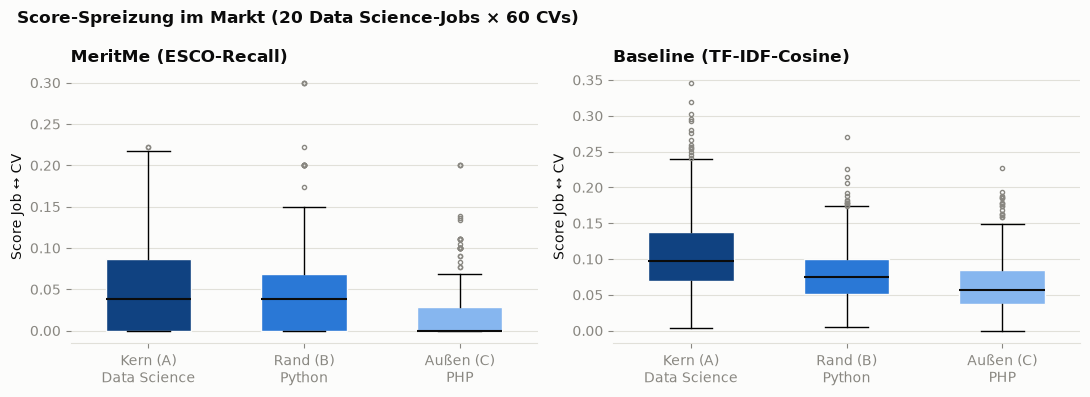

Ring,A,B,C
Methode,,,
MeritMe (ESCO-Recall),0.038,0.038,0.000
Baseline (TF-IDF-Cosine),0.097,0.075,0.057


In [19]:
mlb_m = MultiLabelBinarizer(sparse_output=True).fit(pd.concat([bew_list["uris"], market_jobs["uris"]]))
E_list = mlb_m.transform(bew_list["uris"]).tocsr().astype(float)
E_jobs_m = mlb_m.transform(market_jobs["uris"]).tocsr().astype(float)
score_recall = recall_matrix(E_jobs_m, E_list)                      # 20 Jobs x 60 CVs

tfidf_m = TfidfVectorizer(**TFIDF_PARAMS).fit(pd.concat([bew_list["text"], market_jobs["text"]]))
score_cos = cosine_similarity(tfidf_m.transform(market_jobs["text"]), tfidf_m.transform(bew_list["text"]))

rings = bew_list["ring"].to_numpy()
long = pd.concat([
    pd.DataFrame({"Methode": name, "Ring": np.tile(rings, N_JOBS), "Score": S.ravel()})
    for name, S in [("MeritMe (ESCO-Recall)", score_recall), ("Baseline (TF-IDF-Cosine)", score_cos)]
])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, grp) in zip(axes, long.groupby("Methode", sort=False)):
    data = [grp.loc[grp["Ring"] == r, "Score"] for r in "ABC"]
    bp = ax.boxplot(data, patch_artist=True, widths=0.55, medianprops={"color": INK, "linewidth": 1.5},
                    flierprops={"markersize": 3, "markeredgecolor": MUTED})
    for patch, r in zip(bp["boxes"], "ABC"):
        patch.set_facecolor(RING_COLORS[r])
        patch.set_edgecolor(SURFACE)
    ax.set_xticks([1, 2, 3], [f"{RING_NAMES[r]}\n{RINGS[r]}" for r in "ABC"])
    ax.set_ylabel("Score Job ↔ CV")
    ax.set_title(name, loc="left", color=INK, fontweight="bold")
    ax.grid(axis="x", visible=False)
fig.suptitle(f"Score-Spreizung im Markt (20 {A}-Jobs × 60 CVs)", x=0.02, ha="left", color=INK,
             fontweight="bold", fontsize=12)
plt.tight_layout()
plt.show()

long.groupby(["Methode", "Ring"], sort=False)["Score"].median().unstack().round(3)

### Die Shortlist-Vision: Wer landet oben, wer ganz unten?

Jede Zeile ist ein Job, jede Spalte ein Rangplatz (1 = bester Match). Die Farbe zeigt, aus welchem
Ring der CV auf diesem Platz stammt. Ideal: dunkel (Kern) links, hell (Außen) rechts.
Gleichstände werden zufällig (Seed 42) aufgelöst.

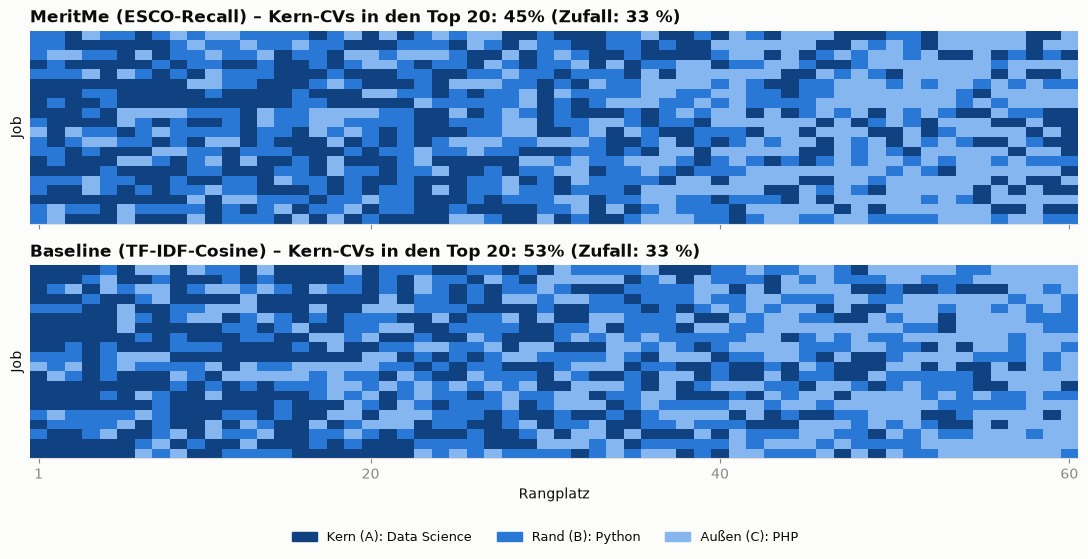

In [20]:
# Gleichstände zufällig (Seed) auflösen – eine stabile Sortierung würde die Listenreihenfolge
# A, B, C übernehmen und den Kern bei Gleichstand künstlich nach oben schieben.
tiebreak = np.random.default_rng(SEED).permutation(len(rings))


def rank_rings(S: np.ndarray) -> np.ndarray:
    order = np.array([np.lexsort((tiebreak, -row)) for row in S])
    return np.vectorize({"A": 0, "B": 1, "C": 2}.get)(rings[order])


ring_cmap = ListedColormap([RING_COLORS[r] for r in "ABC"])
fig, axes = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
for ax, (name, S) in zip(axes, [("MeritMe (ESCO-Recall)", score_recall), ("Baseline (TF-IDF-Cosine)", score_cos)]):
    rr = rank_rings(S)
    ax.imshow(rr, cmap=ring_cmap, aspect="auto", vmin=0, vmax=2, interpolation="nearest")
    top20_a = (rr[:, :N_PER_RING] == 0).mean()
    ax.set_title(f"{name} – Kern-CVs in den Top 20: {top20_a:.0%} (Zufall: 33 %)", loc="left", color=INK, fontweight="bold")
    ax.set_ylabel("Job")
    ax.set_yticks([])
    ax.grid(False)
axes[1].set_xlabel("Rangplatz")
axes[1].set_xticks([0, 19, 39, 59], ["1", "20", "40", "60"])
handles = [plt.Rectangle((0, 0), 1, 1, color=RING_COLORS[r]) for r in "ABC"]
fig.legend(handles, [f"{RING_NAMES[r]}: {RINGS[r]}" for r in "ABC"], frameon=False, ncol=3,
           loc="lower center", bbox_to_anchor=(0.5, -0.02), fontsize=9)
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

### Zwei Fallstricke für den Rankingtest: Gleichstände und Textlänge

- **Gleichstände:** Recall ist ein Bruch mit kleinem Nenner (Anzahl Job-Labels) – viele CVs
  können denselben Score haben. Für den Rangabstand der Zwillinge braucht es dann eine feste
  Tie-Regel (z. B. mittlerer Rang).
- **Textlänge:** Hängt der mittlere Score eines Kern-CVs (über alle 20 Jobs) an seiner Länge
  (Abschnitt 7)? Mit n = 20 CVs nur ein grobes Signal.

In [21]:
rows = []
for name, S in [("MeritMe (ESCO-Recall)", score_recall), ("Baseline (TF-IDF-Cosine)", score_cos)]:
    tied = np.mean([pd.Series(row).duplicated(keep=False).mean() for row in S])
    distinct_ = np.mean([len(np.unique(np.round(row, 6))) for row in S])
    kern = rings == "A"
    rho, p = spearmanr(S[:, kern].mean(axis=0), bew_list.loc[kern, "n_words"])
    rows.append({"Methode": name, "Ø verschiedene Scores (von 60)": distinct_,
                 "Anteil CVs im Gleichstand": tied, "Anteil Score = 0": (S == 0).mean(), "Spearman ρ Ø-Score~Länge (Kern, n=20)": rho, "p": p})
pd.DataFrame(rows).set_index("Methode").round(3)

,Ø verschiedene Scores (von 60),Anteil CVs im Gleichstand,Anteil Score = 0,"Spearman ρ Ø-Score~Länge (Kern, n=20)",p
Methode,,,,,
MeritMe (ESCO-Recall),4.3,0.992,0.400,0.065,0.784
Baseline (TF-IDF-Cosine),60.0,0.000,0.001,0.038,0.875


### Wo landen die Zwillings-Quellen in ihrer Liste?

Ein Zwilling ist nur so aussagekräftig wie die Position, an der er in die Liste fällt. Hat der
Ausgangs-CV zu seinem Job Score 0, landen beide Zwillinge im großen Gleichstandsblock ganz unten –
ihr Rangabstand wäre dort bedeutungslos. Wir reihen deshalb jeden Ausgangs-CV probehalber in die
Liste seines Jobs ein (bei Gleichstand: mittlerer Rang des Blocks) und schauen getrennt nach Ring.

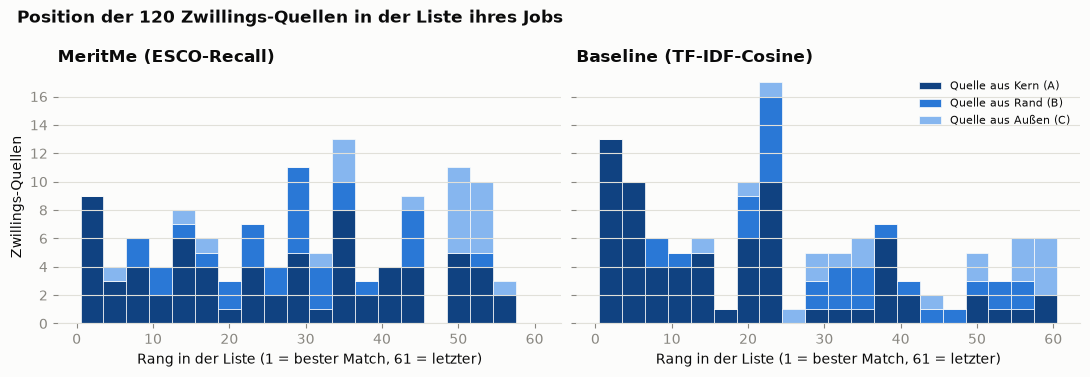

n  Anteil Score = 0  Median Rang  Anteil in Top 20  \
Methode  Ring                                                             
MeritMe  Kern (A)   70              0.33        27.25              0.40   
         Rand (B)   30              0.20        28.75              0.20   
         Außen (C)  20              0.70        49.25              0.15   
Baseline Kern (A)   70              0.00        15.00              0.59   
         Rand (B)   30              0.00        32.00              0.17   
         Außen (C)  20              0.00        46.00              0.10   

                    Ø Gleichstandsblock  
Methode  Ring                            
MeritMe  Kern (A)                 22.19  
         Rand (B)                 26.30  
         Außen (C)                21.75  
Baseline Kern (A)                  1.00  
         Rand (B)                  1.00  
         Außen (C)                 1.00

In [22]:
job_pos = {jid: i for i, jid in enumerate(market_jobs["id"])}
ji = twin_sources["assigned_job_id"].map(job_pos).to_numpy()
job_sets = [set(u) for u in market_jobs["uris"]]
ts_recall = np.array([len(set(u) & job_sets[j]) / len(job_sets[j]) for u, j in zip(twin_sources["uris"], ji)])
X_ts = tfidf_m.transform(twin_sources["text"])
X_jobs_m = tfidf_m.transform(market_jobs["text"])
ts_cos = np.array([cosine_similarity(X_ts[i], X_jobs_m[j])[0, 0] for i, j in enumerate(ji)])


def insert_rank(S: np.ndarray, scores: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    greater = np.array([(S[j] > s).sum() for j, s in zip(ji, scores)])
    equal = np.array([(S[j] == s).sum() for j, s in zip(ji, scores)])
    return greater + 1 + equal / 2, equal + 1   # mittlerer Rang, Größe des Gleichstandsblocks


rank_recall, block_recall = insert_rank(score_recall, ts_recall)
rank_cos, block_cos = insert_rank(score_cos, ts_cos)

ts_ring = twin_sources["ring"].to_numpy()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, (name, rk) in zip(axes, [("MeritMe (ESCO-Recall)", rank_recall), ("Baseline (TF-IDF-Cosine)", rank_cos)]):
    ax.hist([rk[ts_ring == r] for r in "ABC"], bins=np.arange(0.5, 62.5, 3), stacked=True,
            color=[RING_COLORS[r] for r in "ABC"], edgecolor=SURFACE, linewidth=0.5,
            label=[f"Quelle aus {RING_NAMES[r]}" for r in "ABC"])
    ax.set_xlabel("Rang in der Liste (1 = bester Match, 61 = letzter)")
    ax.set_title(name, loc="left", color=INK, fontweight="bold")
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Zwillings-Quellen")
axes[1].legend(frameon=False, fontsize=8, loc="upper right")
fig.suptitle("Position der 120 Zwillings-Quellen in der Liste ihres Jobs", x=0.02, ha="left",
             color=INK, fontweight="bold", fontsize=12)
plt.tight_layout()
plt.show()

rows = []
for name, sc, rk, bl in [("MeritMe", ts_recall, rank_recall, block_recall), ("Baseline", ts_cos, rank_cos, block_cos)]:
    for r in "ABC":
        m = ts_ring == r
        rows.append({"Methode": name, "Ring": RING_NAMES[r], "n": m.sum(),
                     "Anteil Score = 0": (sc[m] == 0).mean(), "Median Rang": np.median(rk[m]),
                     "Anteil in Top 20": (rk[m] <= 20).mean(), "Ø Gleichstandsblock": bl[m].mean()})
pd.DataFrame(rows).set_index(["Methode", "Ring"]).round(2)

### Export

Die Auswahl wird als ID-Liste eingefroren – Grundlage für die Zwillingsgenerierung und den
Rankingtest. Texte und Labels werden nicht mitgespeichert; sie lassen sich über `id` aus den
Rohdaten und deterministisch über ESCOX rekonstruieren.

In [23]:
export = pd.concat([bew_list, market_jobs, twin_sources], ignore_index=True)
export = export.reindex(columns=["id", "doc_type", "role", "ring", "test", "Primary Keyword",
                                 "assigned_job_id", "n_words", "n_labels"]).assign(seed=SEED)
OUT_PATH.parent.mkdir(parents=True, exist_ok=True)
export.to_parquet(OUT_PATH, index=False)

print(f"Gespeichert: {OUT_PATH} ({len(export)} Zeilen)")
export.groupby(["role", "ring"], dropna=False).size()

Gespeichert: ../data/processed/market_v1.parquet (200 Zeilen)


role         ring
job_A        NaN     20
list_A       A       20
list_B       B       20
list_C       C       20
twin_source  A       70
             B       30
             C       20
dtype: int64

## 9. Zusammenfassung

**Zu den Leitfragen:**

- *Welche Primary Keywords haben genug Jobs und CVs?* Alle 25 IT-Keywords, die Menge ist kein Kriterium. Der Markt wird fachlich vorgegeben und in beiden Räumen geprüft: **Data Science (Kern) / Python (Rand) / PHP (Außen, regelbasiert)**. Ausgestochen wird nur über das methodenneutrale `Primary Keyword`.
- *Welche ESCO-Labels matchen gut?* Für Data Science *data science*, *machine learning*, *data mining* und *statistics*, allerdings selten in CVs. Viel Rauschen kommt aus Jobs (*assume responsibility*, *interact with users to gather requirements*, Sprach-Labels) und aus ESCOX-Fehltreffern. Werkzeuge wie Airflow und Databricks fehlen in ESCO.
- *Welche CV-Spalten geben wir ESCOX?* `Position + Highlights + Moreinfo`, ohne `Looking For`. Das gilt für beide Methoden gleich (ARI der CVs 0,30 → 0,37).

**Ergebnis:** `data/processed/market_v1.parquet` enthält 60 Listen-CVs (20/20/20), 20 Data-Science-Jobs und 120 Zwillings-Quellen, Seed 42: **70 aus A + 30 aus B als Haupttest** (100 Paare, wie im Plan) und **20 aus C als Kontrolle**. Jeder Job bekommt 6 Paare (5 Haupttest + 1 Kontrolle). Die Kontrolle wird nicht in den Wilcoxon-Test gemischt. Ein erneuter Lauf erzeugt dieselben IDs. Die Datei ist noch nicht eingecheckt.

**Der wichtigste Befund ist ein Risiko für den Rankingtest (Stufe 2).** Im Markt ist die Baseline sauber gestaffelt (Median Kern 0,097 > Rand 0,075 > Außen 0,057). Der MeritMe-Recall unterscheidet Kern und Rand dagegen nicht (Median 0,038 = 0,038 > Außen 0) und erzeugt im Mittel nur **4 verschiedene Scores für 60 CVs** (99 % im Gleichstand, 40 % Score 0). Für die Zwillinge heißt das konkret:

| Zwillings-Quellen | n | Score 0 (MeritMe) | Median Rang MeritMe | Median Rang Baseline | Ø Gleichstandsblock MeritMe |
|---|---|---|---|---|---|
| Kern (A) | 70 | 33 % | 27 | 15 | 22 Plätze |
| Rand (B) | 30 | 20 % | 29 | 32 | 26 Plätze |
| Außen (C, Kontrolle) | 20 | 70 % | 49 | 46 | 22 Plätze |

- Die Baseline staffelt auch die Zwillings-Quellen klar (Median 15 → 32 → 46). MeritMe setzt A- und B-Quellen auf **dieselbe Höhe** (27 / 29), B-Quellen haben sogar seltener Score 0, weil sie die häufigen Labels *Python* und *SQL* teilen.
- Ihr Rang ist bei MeritMe im Mittel auf **über 20 Plätze unbestimmt** (Gleichstandsblock). Bei der Baseline ist jeder Rang eindeutig.
- Die Kontrolle bestätigt die Erwartung: 70 % der C-Quellen landen bei MeritMe bei Score 0, ganz unten.
- Landen beide Zwillinge im selben Block, ist ihr Abstand 0. MeritMe „gewinnt“ dann durch **Grobkörnigkeit statt durch Fairness**, genau die Grenze, die das Feedback benennt. Unterscheidet sich ein einziges Label, springt der Zwilling über einen ganzen Block.

Vor dem Ranking-Test in Sprint 4 sollte das Team über diese Hebel entscheiden (keine Entscheidung der EDA):

1. **Feste Tie-Regel** (z. B. mittlerer Rang) und Gleichstände im Ergebnis mitberichten
2. **Feinere Scores**, z. B. gewichtete Labels oder die im Antrag vorgesehene Tree-Distance (Wu-Palmer)
3. **Rausch-Labels in Jobs** (Boilerplate, Sprach-Labels, Fehltreffer) heruntergewichten, damit der Recall-Nenner nicht künstlich wächst

**Proxy-Kanal im ESCO-Raum:** Die Zahl der Labels steigt mit der Textlänge (ρ = 0,73) und damit mit Erfahrung und Englischniveau. Im Markt selbst ist kein Längeneffekt auf den Score messbar (ρ = 0,07 bzw. 0,04, n = 20 Kern-CVs). → Bei den Zwillingen trotzdem die **Länge konstant halten**.

**Grenzen:**

- **Seniorität nicht kontrolliert:** Ein Junior-CV kann einem Senior-Job zugeordnet sein. Dem Datensatz fehlt eine Grundlage dafür, ab wie vielen Jahren welche Stufe zu welchem Job passt. Erfahrung fließt in MeritMe bewusst nicht ein.
- **Mindestens 5 Labels pro CV:** Bei einem CV mit genau 5 Labels drückt schon *ein* veränderter Label den Jaccard der Zwillinge auf 0,80 bzw. 0,83, also unter die Schwelle von 0,85. Die Schwelle gilt für den Mittelwert, einzelne kurze Profile können ihn aber merklich senken.
- **Ringe sind keine Ground Truth.** Hybride Profile (z. B. Python-Entwickler:innen mit ML-Erfahrung) liegen fachlich womöglich näher am Kern, als ihr Keyword sagt. Die Ringe sollen nur die Spreizung herstellen.
- **Kleine Stichproben:** Screening auf 60 CVs + 20 Jobs pro Keyword, Markt auf 20 Jobs × 60 CVs. ESCOX mit Schwellwert 0,5 unverändert. ESCO-Lücken nur grob per Einzelwort geprüft.

**Nächste Schritte:** Zwillingsgenerierung aus den 100 Zwillings-Quellen. Entscheidung über Tie-Regel und Score-Verfeinerung vor dem Ranking-Test. Batch-Cache für ESCOX (separater Branch).